# 📷 Belajar Pengolahan Citra (OpenCV) Praktis
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

Notebook interaktif 50 topik belajar Computer Vision dan Image Processing menggunakan OpenCV & Python. Dilengkapi kode mandiri dan visualisasi langsung.


### Import OpenCV & NumPy


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version : {np.__version__}")


OpenCV version: 4.14.0
NumPy version : 2.2.6


### Helper Fungsi Visualisasi


In [2]:
def tampilkan(citra, judul="", ukuran=(4, 4), cmap=None):
    plt.figure(figsize=ukuran)
    if len(citra.shape) == 3:
        plt.imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(citra, cmap=cmap or 'gray')
    if judul:
        plt.title(judul)
    plt.axis('off')
    plt.show()


### Membaca Gambar (cv2.imread)


In [3]:
# Membuat gambar sampel sintetis untuk latihan
sampel_awal = np.zeros((300, 300, 3), dtype=np.uint8)
cv2.rectangle(sampel_awal, (50, 50), (250, 250), (0, 140, 255), -1)
cv2.circle(sampel_awal, (150, 150), 60, (255, 255, 255), -1)
cv2.imwrite("sampel.jpg", sampel_awal)

# Membaca gambar dari file
img = cv2.imread("sampel.jpg")
print("Gambar berhasil dibaca. Tipe objek:", type(img))


Gambar berhasil dibaca. Tipe objek: <class 'numpy.ndarray'>


### Menampilkan Gambar (cv2_imshow & Matplotlib)


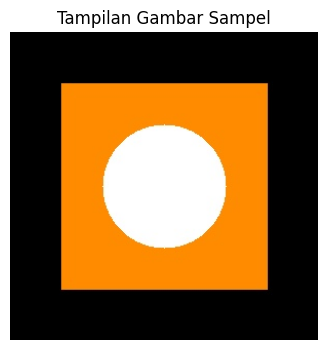

In [4]:
# Di Google Colab gunakan: from google.colab.patches import cv2_imshow; cv2_imshow(img)
# Di notebook umum / Colab dapat menggunakan Matplotlib:
tampilkan(img, "Tampilan Gambar Sampel")


### Menyimpan Gambar (cv2.imwrite)


In [5]:
status_simpan = cv2.imwrite("hasil_simpan.png", img)
print("Penyimpanan berhasil:", status_simpan)


Penyimpanan berhasil: True


### Properti Citra (Resolusi & Channel)


In [6]:
tinggi, lebar, channel = img.shape
print(f"Tinggi (baris) : {tinggi} px")
print(f"Lebar (kolom)  : {lebar} px")
print(f"Jumlah channel : {channel} (BGR)")
print(f"Tipe data      : {img.dtype}")


Tinggi (baris) : 300 px
Lebar (kolom)  : 300 px
Jumlah channel : 3 (BGR)
Tipe data      : uint8


### Akses Nilai Piksel BGR


In [7]:
# Nilai piksel di titik y=150, x=150
b, g, r = img[150, 150]
print(f"Piksel pada (150, 150) -> Blue: {b}, Green: {g}, Red: {r}")


Piksel pada (150, 150) -> Blue: 255, Green: 255, Red: 255


### Modifikasi Piksel Manual


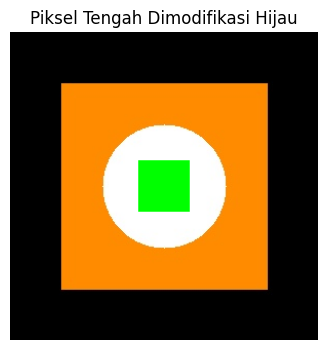

In [8]:
img_mod = img.copy()
# Mengubah area kotak 50x50 menjadi warna hijau (B=0, G=255, R=0)
img_mod[125:175, 125:175] = [0, 255, 0]
tampilkan(img_mod, "Piksel Tengah Dimodifikasi Hijau")


### Membuat Kanvas Kosong


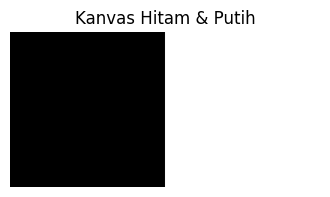

In [9]:
# Kanvas hitam dan kanvas putih
kanvas_hitam = np.zeros((200, 200, 3), dtype=np.uint8)
kanvas_putih = np.full((200, 200, 3), 255, dtype=np.uint8)

tampilkan(np.hstack([kanvas_hitam, kanvas_putih]), "Kanvas Hitam & Putih")


### Mengubah Ukuran Gambar (Resize)


Ukuran baru: (150, 150, 3)


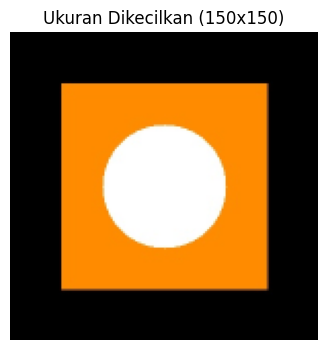

In [10]:
# Resize ke ukuran spesifik (lebar=150, tinggi=150)
img_kecil = cv2.resize(img, (150, 150), interpolation=cv2.INTER_AREA)
print(f"Ukuran baru: {img_kecil.shape}")
tampilkan(img_kecil, "Ukuran Dikecilkan (150x150)")


### Memotong Gambar (Cropping)


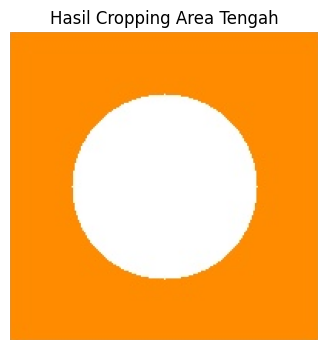

In [11]:
# Slicing array [y_start:y_end, x_start:x_end]
crop = img[50:250, 50:250]
tampilkan(crop, "Hasil Cropping Area Tengah")


### Translasi Gambar


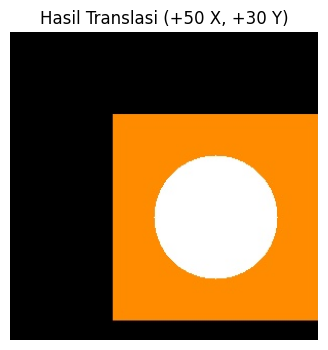

In [12]:
# Matriks translasi: geser sumbu X +50px, sumbu Y +30px
M_translasi = np.float32([[1, 0, 50], [0, 1, 30]])
img_geser = cv2.warpAffine(img, M_translasi, (lebar, tinggi))
tampilkan(img_geser, "Hasil Translasi (+50 X, +30 Y)")


### Rotasi Gambar


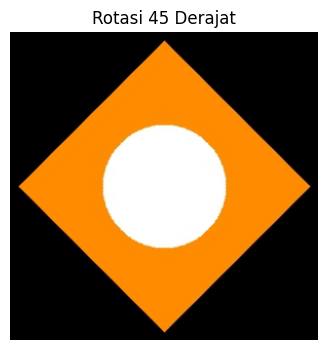

In [13]:
pusat = (lebar // 2, tinggi // 2)
M_rotasi = cv2.getRotationMatrix2D(pusat, angle=45, scale=1.0)
img_putar = cv2.warpAffine(img, M_rotasi, (lebar, tinggi))
tampilkan(img_putar, "Rotasi 45 Derajat")


### Membalik Gambar (Flipping)


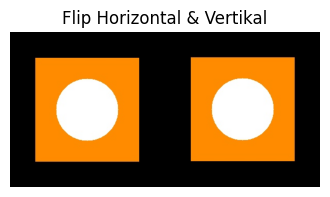

In [14]:
# 0: vertikal, 1: horizontal, -1: keduanya
flip_h = cv2.flip(img, 1)
flip_v = cv2.flip(img, 0)
tampilkan(np.hstack([flip_h, flip_v]), "Flip Horizontal & Vertikal")


### Menggambar Garis


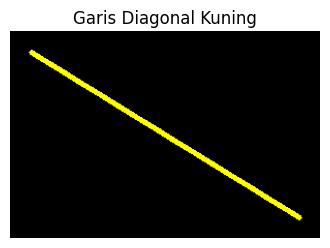

In [15]:
kanvas_garis = np.zeros((200, 300, 3), dtype=np.uint8)
cv2.line(kanvas_garis, (20, 20), (280, 180), (0, 255, 255), thickness=4)
tampilkan(kanvas_garis, "Garis Diagonal Kuning")


### Menggambar Persegi dan Lingkaran


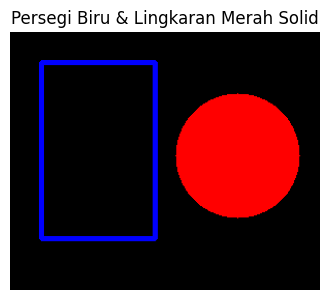

In [16]:
kanvas_bentuk = np.zeros((250, 300, 3), dtype=np.uint8)
cv2.rectangle(kanvas_bentuk, (30, 30), (140, 200), (255, 0, 0), thickness=3)
cv2.circle(kanvas_bentuk, (220, 120), 60, (0, 0, 255), thickness=-1)
tampilkan(kanvas_bentuk, "Persegi Biru & Lingkaran Merah Solid")


### Menambahkan Teks pada Gambar


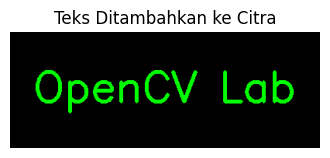

In [17]:
kanvas_teks = np.zeros((150, 400, 3), dtype=np.uint8)
cv2.putText(kanvas_teks, "OpenCV Lab", (30, 90), cv2.FONT_HERSHEY_SIMPLEX, 1.8, (0, 255, 0), 3)
tampilkan(kanvas_teks, "Teks Ditambahkan ke Citra")


### Konversi BGR ke Grayscale


Shape grayscale: (300, 300)


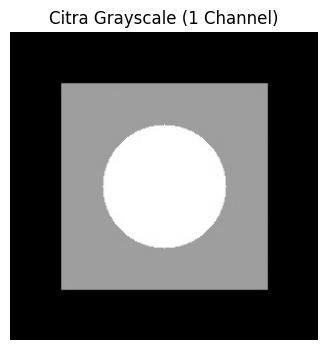

In [18]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Shape grayscale:", gray.shape)
tampilkan(gray, "Citra Grayscale (1 Channel)")


### Konversi ke Ruang Warna HSV


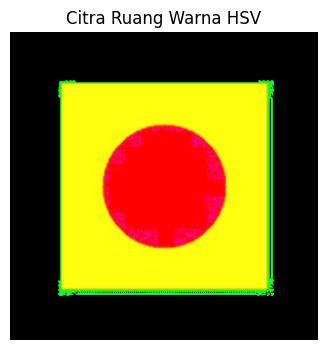

In [19]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
tampilkan(hsv, "Citra Ruang Warna HSV")


### Memisahkan Channel Warna (Split)


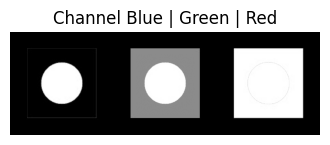

In [20]:
b_ch, g_ch, r_ch = cv2.split(img)
tampilkan(np.hstack([b_ch, g_ch, r_ch]), "Channel Blue | Green | Red")


### Menggabungkan Channel Warna (Merge)


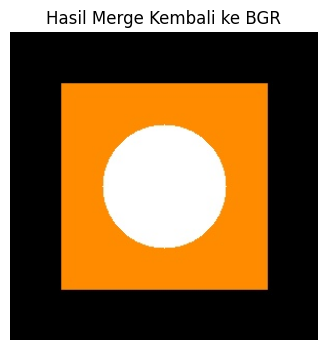

In [21]:
merged = cv2.merge([b_ch, g_ch, r_ch])
tampilkan(merged, "Hasil Merge Kembali ke BGR")


### Simple Thresholding


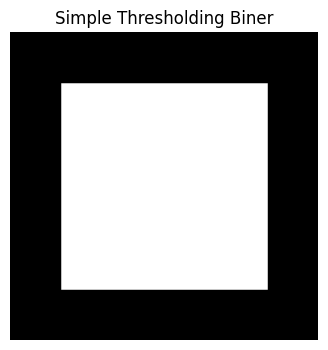

In [22]:
# Nilai piksel > 127 diubah jadi 255, sisanya 0
ret, thresh_simple = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
tampilkan(thresh_simple, "Simple Thresholding Biner")


### Adaptive Thresholding


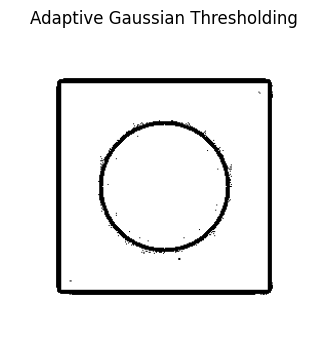

In [23]:
thresh_adaptif = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
)
tampilkan(thresh_adaptif, "Adaptive Gaussian Thresholding")


### Otsu's Thresholding


Ambang batas optimal Otsu: 13.0


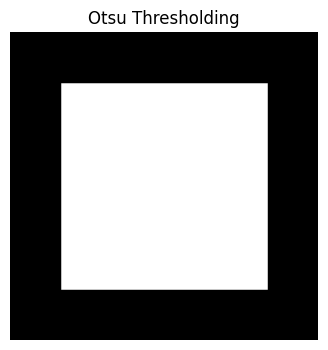

In [24]:
ret_otsu, thresh_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Ambang batas optimal Otsu: {ret_otsu}")
tampilkan(thresh_otsu, "Otsu Thresholding")


### Membalik Warna Citra (Invert)


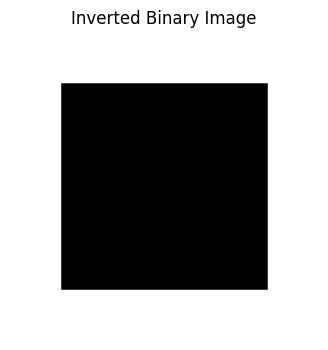

In [25]:
invert_img = cv2.bitwise_not(thresh_simple)
tampilkan(invert_img, "Inverted Binary Image")


### Custom Filter dan Konvolusi 2D


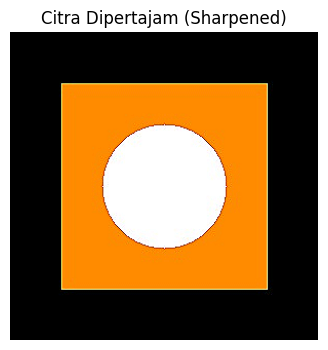

In [26]:
# Kernel penajaman (Sharpening kernel)
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])
tajam = cv2.filter2D(img, -1, kernel_sharpen)
tampilkan(tajam, "Citra Dipertajam (Sharpened)")


### Averaging Blur


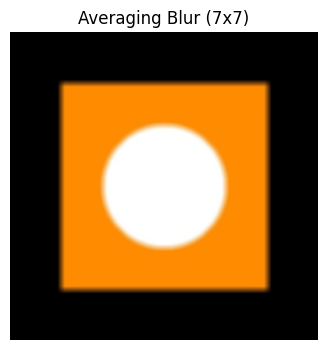

In [27]:
blur_rata = cv2.blur(img, (7, 7))
tampilkan(blur_rata, "Averaging Blur (7x7)")


### Gaussian Blur


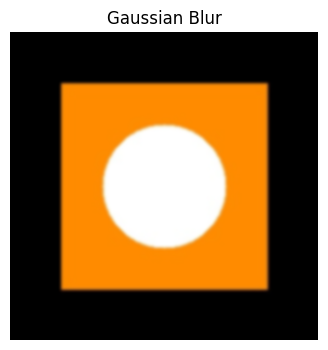

In [28]:
blur_gaussian = cv2.GaussianBlur(img, (7, 7), sigmaX=0)
tampilkan(blur_gaussian, "Gaussian Blur")


### Median Blur


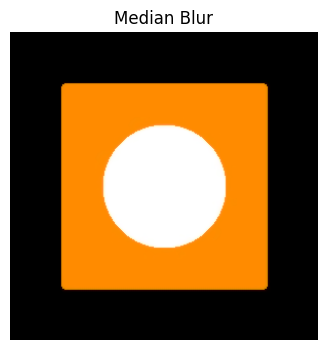

In [29]:
# Sangat efektif meredam salt-and-pepper noise
blur_median = cv2.medianBlur(img, 7)
tampilkan(blur_median, "Median Blur")


### Bilateral Filter


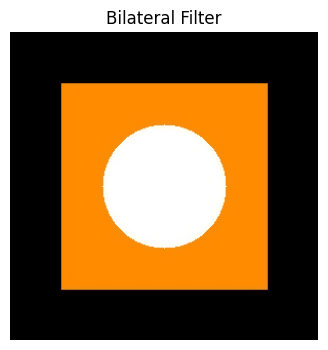

In [30]:
# Menghaluskan permukaan namun menjaga tepian tajam
bilateral = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)
tampilkan(bilateral, "Bilateral Filter")


### Deteksi Tepi Sobel


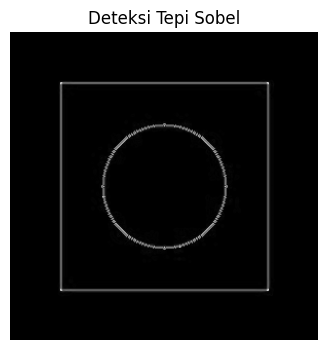

In [31]:
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_gabung = cv2.magnitude(sobelx, sobely)

tampilkan(np.uint8(np.absolute(sobel_gabung)), "Deteksi Tepi Sobel")


### Deteksi Tepi Laplacian


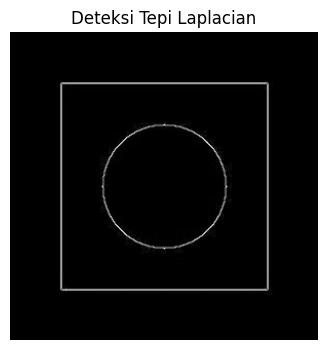

In [32]:
laplacian = cv2.Laplacian(gray, cv2.CV_64F)
tampilkan(np.uint8(np.absolute(laplacian)), "Deteksi Tepi Laplacian")


### Canny Edge Detection


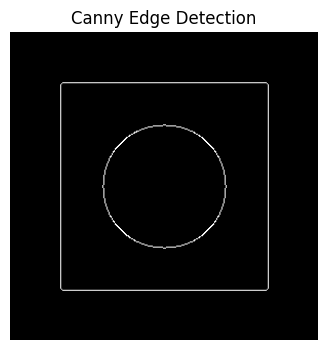

In [33]:
edges = cv2.Canny(gray, threshold1=50, threshold2=150)
tampilkan(edges, "Canny Edge Detection")


### Operasi Morfologi Erosi


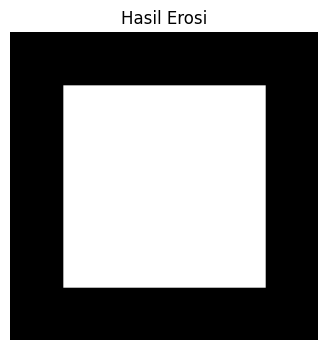

In [34]:
kernel_morf = np.ones((5, 5), np.uint8)
erosi = cv2.erode(thresh_simple, kernel_morf, iterations=1)
tampilkan(erosi, "Hasil Erosi")


### Operasi Morfologi Dilasi


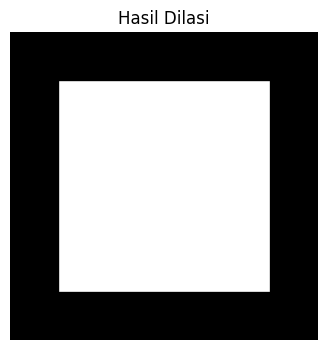

In [35]:
dilasi = cv2.dilate(thresh_simple, kernel_morf, iterations=1)
tampilkan(dilasi, "Hasil Dilasi")


### Morfologi Opening


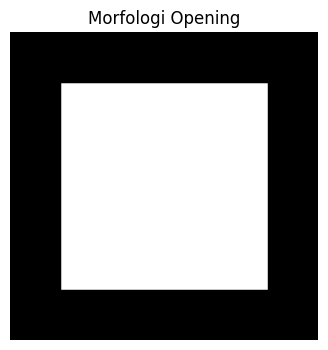

In [36]:
# Erosi dilanjutkan Dilasi
opening = cv2.morphologyEx(thresh_simple, cv2.MORPH_OPEN, kernel_morf)
tampilkan(opening, "Morfologi Opening")


### Morfologi Closing


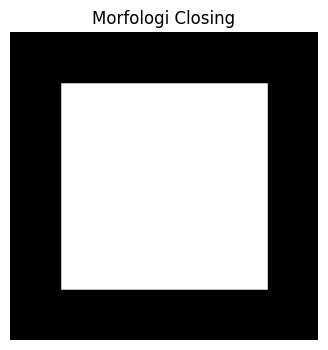

In [37]:
# Dilasi dilanjutkan Erosi
closing = cv2.morphologyEx(thresh_simple, cv2.MORPH_CLOSE, kernel_morf)
tampilkan(closing, "Morfologi Closing")


### Deteksi Kontur (findContours)


In [38]:
contours, hierarchy = cv2.findContours(thresh_simple, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
print(f"Jumlah kontur terdeteksi: {len(contours)}")


Jumlah kontur terdeteksi: 1


### Menggambar Kontur (drawContours)


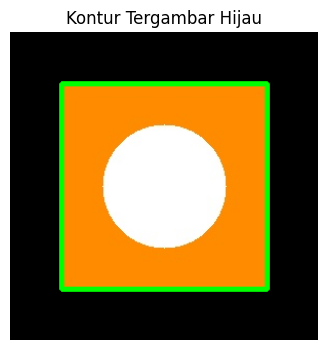

In [39]:
img_kontur = img.copy()
cv2.drawContours(img_kontur, contours, -1, (0, 255, 0), thickness=3)
tampilkan(img_kontur, "Kontur Tergambar Hijau")


### Bounding Box pada Objek


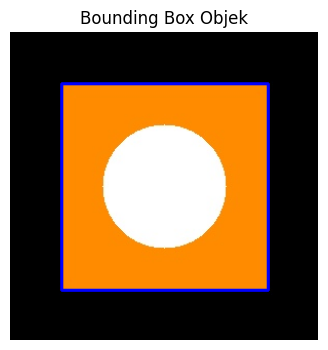

In [40]:
img_bbox = img.copy()
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.rectangle(img_bbox, (x, y), (x + w, y + h), (255, 0, 0), 2)
tampilkan(img_bbox, "Bounding Box Objek")


### Menghitung Luas Area dan Keliling Kontur


In [41]:
for idx, cnt in enumerate(contours):
    luas = cv2.contourArea(cnt)
    keliling = cv2.arcLength(cnt, closed=True)
    print(f"Kontur #{idx+1} -> Luas: {luas:.1f} px^2 | Keliling: {keliling:.1f} px")


Kontur #1 -> Luas: 40000.0 px^2 | Keliling: 800.0 px


### Operasi Bitwise (AND, OR, XOR)


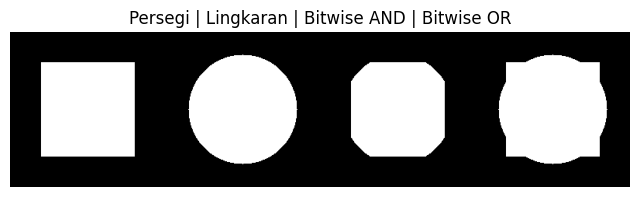

In [42]:
persegi_biner = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(persegi_biner, (40, 40), (160, 160), 255, -1)

lingkaran_biner = np.zeros((200, 200), dtype=np.uint8)
cv2.circle(lingkaran_biner, (100, 100), 70, 255, -1)

bit_and = cv2.bitwise_and(persegi_biner, lingkaran_biner)
bit_or = cv2.bitwise_or(persegi_biner, lingkaran_biner)

tampilkan(np.hstack([persegi_biner, lingkaran_biner, bit_and, bit_or]), "Persegi | Lingkaran | Bitwise AND | Bitwise OR", ukuran=(8, 3))


### Image Masking


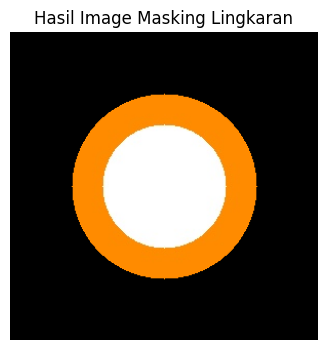

In [43]:
mask = np.zeros(img.shape[:2], dtype=np.uint8)
cv2.circle(mask, (150, 150), 90, 255, -1)
img_masked = cv2.bitwise_and(img, img, mask=mask)

tampilkan(img_masked, "Hasil Image Masking Lingkaran")


### Kalkulasi Histogram Warna


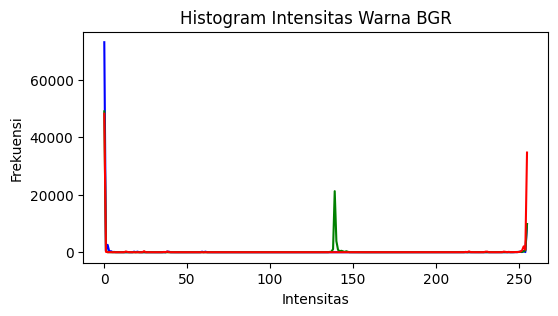

In [44]:
plt.figure(figsize=(6, 3))
warna = ('b', 'g', 'r')
for i, col in enumerate(warna):
    hist = cv2.calcHist([img], [i], None, [256], [0, 256])
    plt.plot(hist, color=col)
plt.title("Histogram Intensitas Warna BGR")
plt.xlabel("Intensitas")
plt.ylabel("Frekuensi")
plt.show()


### Histogram Equalization


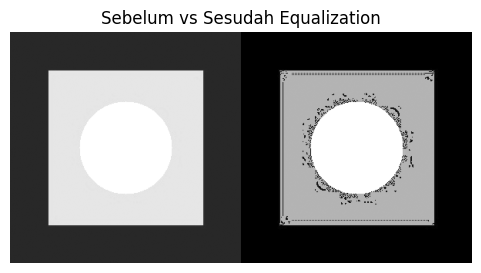

In [45]:
img_terang = cv2.convertScaleAbs(gray, alpha=1.2, beta=40)
equ = cv2.equalizeHist(img_terang)
tampilkan(np.hstack([img_terang, equ]), "Sebelum vs Sesudah Equalization", ukuran=(6, 3))


### CLAHE (Adaptive Histogram Equalization)


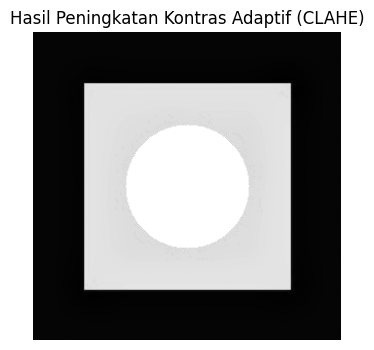

In [46]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
cl_img = clahe.apply(img_terang)
tampilkan(cl_img, "Hasil Peningkatan Kontras Adaptif (CLAHE)")


### Template Matching


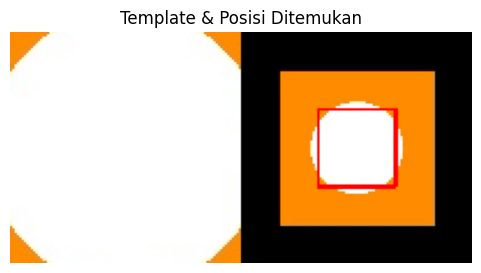

In [47]:
# Mengambil potongan template dari gambar
template = img[100:200, 100:200]
res = cv2.matchTemplate(img, template, cv2.TM_CCOEFF_NORMED)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

img_match = img.copy()
h_t, w_t = template.shape[:2]
cv2.rectangle(img_match, max_loc, (max_loc[0] + w_t, max_loc[1] + h_t), (0, 0, 255), 3)

tampilkan(np.hstack([cv2.resize(template, (w_t, h_t)), cv2.resize(img_match, (w_t, h_t))]), "Template & Posisi Ditemukan", ukuran=(6, 3))


### Deteksi Wajah dengan Haar Cascades


Classifier Haar Cascade aktif. Wajah terdeteksi: 0


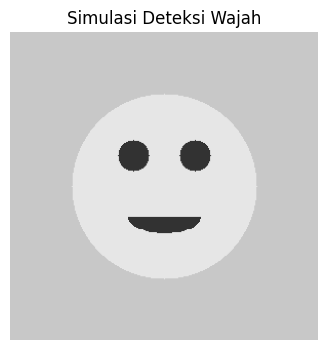

In [48]:
# Memuat cascade classifier bawaan OpenCV
cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(cascade_path)

# Kanvas wajah sederhana untuk demonstrasi
kanvas_wajah = np.full((300, 300, 3), 200, dtype=np.uint8)
cv2.circle(kanvas_wajah, (150, 150), 90, (230, 230, 230), -1)
cv2.circle(kanvas_wajah, (120, 120), 15, (50, 50, 50), -1)
cv2.circle(kanvas_wajah, (180, 120), 15, (50, 50, 50), -1)
cv2.ellipse(kanvas_wajah, (150, 180), (35, 15), 0, 0, 180, (50, 50, 50), -1)

faces = face_cascade.detectMultiScale(cv2.cvtColor(kanvas_wajah, cv2.COLOR_BGR2GRAY), 1.1, 4)
for (fx, fy, fw, fh) in faces:
    cv2.rectangle(kanvas_wajah, (fx, fy), (fx + fw, fy + fh), (0, 255, 0), 2)

print(f"Classifier Haar Cascade aktif. Wajah terdeteksi: {len(faces)}")
tampilkan(kanvas_wajah, "Simulasi Deteksi Wajah")


### Membaca File Video


In [49]:
# Membuat file video demo 30 frame
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_video = cv2.VideoWriter("demo_video.mp4", fourcc, 15.0, (200, 200))
for i in range(30):
    frame = np.zeros((200, 200, 3), dtype=np.uint8)
    cv2.circle(frame, (30 + i * 4, 100), 20, (0, 255, 255), -1)
    out_video.write(frame)
out_video.release()

# Membaca video kembali
cap = cv2.VideoCapture("demo_video.mp4")
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Video dimuat: {total_frames} frame pada {fps} FPS")


Video dimuat: 30 frame pada 15.0 FPS


### Ekstraksi Frame dari Video


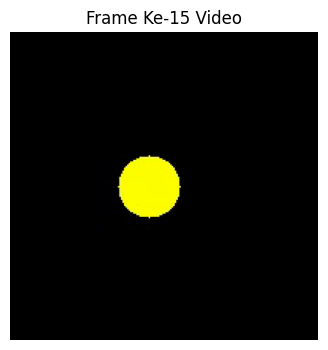

In [50]:
cap.set(cv2.CAP_PROP_POS_FRAMES, 15)
ret, frame_15 = cap.read()
if ret:
    cv2.imwrite("frame_15.jpg", frame_15)
    tampilkan(frame_15, "Frame Ke-15 Video")
cap.release()


### Membuat dan Menyimpan File Video (VideoWriter)


In [51]:
# Menulis video baru dari frame termodifikasi
out_final = cv2.VideoWriter("hasil_video.mp4", fourcc, 15.0, (200, 200))
for i in range(20):
    fr = np.zeros((200, 200, 3), dtype=np.uint8)
    cv2.putText(fr, f"F:{i}", (50, 110), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 2)
    out_final.write(fr)
out_final.release()
print("File video baru berhasil disimpan sebagai hasil_video.mp4")


File video baru berhasil disimpan sebagai hasil_video.mp4
